# Chapter 13 | Worked solutions

*Structured State Spaces and Long Convolutions*

## Goal

Work through all eleven exercises, from a one-number memory to a changing
state update. Track where each input is written, how often it is carried,
and when it is read. The central checks compare a recurrence with its
convolution, distinguish a compact state from the full history, and expose
future leakage from an FFT that is too short. Exercises 9-11 are optional.
Both PDF editions contain every explanation, result, and diagram; the
notebook edition also includes the code and its recorded outputs.

## Setup

Run inside `transformers-book` on CPU with the repository requirements,
plus `matplotlib` and Jupyter installed. No model or dataset download is
needed. The saved run uses Python 3.12 and NumPy 2.4. Exact counts and binary
fractions use exact comparisons where appropriate; FFT and other
floating-point checks use a stated tolerance.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch13_state_spaces"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

import io
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE, TEAL, ORANGE = "#3976af", "#46856e", "#bb783d"

def show_plot(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


## 1. Follow one state

Each step keeps one quarter of the old state, then adds the new input.
Start with $x_0=0$. The state is read **after** adding the current input.

| Position $t$ | Input $u_t$ | Retained old state | Updated state $x_t$ |
| --- | --- | --- | --- |
| 1 | 4 | $(1/4)0=0$ | $4$ |
| 2 | 0 | $(1/4)4=1$ | $1$ |
| 3 | 0 | $(1/4)1=1/4$ | $1/4$ |
| 4 | 2 | $(1/4)(1/4)=1/16$ | $1/16+2=33/16$ |

Thus the states are $(4,1,0.25,2.0625)$. The first input crosses three
transitions before the fourth output, contributing $4(1/4)^3=1/16$.
The newest input contributes $2$ immediately, with lag zero.

For the shorter history $(4,0)$, the states are $(4,1)$. For $(0,1)$,
they are $(0,1)$. Both leave **the same state, 1**, after two inputs.
The state alone cannot distinguish those histories. Applying the same
future inputs gives the same future states, even though the earlier
outputs differed. A state can be sufficient to continue this recurrence
without being a lossless record of the inputs.

In [2]:
from examples.ch13_state_spaces.model import ssm_scan

scalar_model = (np.array([[0.25]]), np.array([1.0]), np.array([1.0]))
scalar_output, scalar_states = ssm_scan([4, 0, 0, 2], *scalar_model)
np.testing.assert_array_equal(scalar_output, [4, 1, 0.25, 2.0625])
hist_a, state_a = ssm_scan([4, 0], *scalar_model)
hist_b, state_b = ssm_scan([0, 1], *scalar_model)
np.testing.assert_array_equal(state_a[-1], state_b[-1])
print("States:", scalar_states[:, 0])
print("First-input contribution at t=4:", 4 * 0.25**3)
print("Two histories:", hist_a, hist_b)
print("Their final states:", state_a[-1], state_b[-1])

States: [4.     1.     0.25   2.0625]
First-input contribution at t=4: 0.0625
Two histories: [4. 1.] [0. 1.]
Their final states: [1.] [1.]


## 2. Read by lag

An input enters with coefficient one. Each later transition multiplies
its contribution by $1/4$, so the filter tap at lag $\ell$ is
$k_\ell=(1/4)^\ell$. The first four taps are

$$
(k_0,k_1,k_2,k_3)=(1,1/4,1/16,1/64).
$$

The first tap multiplies the current input, not the oldest input.
For $u=(4,0,0,2)$,

$$
y_3=k_0u_3+k_1u_2+k_2u_1=0+0+(1/16)4=1/4,
$$

$$
y_4=k_0u_4+k_1u_3+k_2u_2+k_3u_1
    =2+0+0+(1/64)4=33/16.
$$

These match the third and fourth states. The recurrence applies a factor
of $1/4$ at each intervening step; the filter already contains the product
of those factors. A unit impulse, followed by zeros, therefore returns
the filter itself.

In [3]:
from examples.ch13_state_spaces.model import ssm_kernel, causal_convolution

scalar_filter = ssm_kernel(*scalar_model, length=4)
scalar_convolution = causal_convolution([4, 0, 0, 2], scalar_filter)
impulse_output, _ = ssm_scan([1, 0, 0, 0], *scalar_model)
np.testing.assert_array_equal(scalar_filter, [1, 0.25, 0.0625, 0.015625])
np.testing.assert_array_equal(scalar_convolution, scalar_output)
np.testing.assert_array_equal(impulse_output, scalar_filter)
print("Lag-ordered taps:", scalar_filter)
print("Convolution:", scalar_convolution)

Lag-ordered taps: [1.       0.25     0.0625   0.015625]
Convolution: [4.     1.     0.25   2.0625]


## 3. Carry two features

Write the state as $(p_t,q_t)^\top$. The two coordinates receive the same
input but retain different fractions of their previous values:

$$
p_t=\tfrac12p_{t-1}+u_t,\qquad
q_t=\tfrac34q_{t-1}+u_t,\qquad y_t=p_t-q_t.
$$

| Position | Input | First coordinate $p_t$ | Second coordinate $q_t$ | Readout $y_t$ |
| --- | --- | --- | --- | --- |
| 1 | 4 | 4 | 4 | 0 |
| 2 | 0 | 2 | 3 | $-1$ |
| 3 | 0 | 1 | $9/4$ | $-5/4$ |

The outputs are $(0,-1,-1.25)$. A zero input stops adding new information;
it does not freeze the stored state. The first coordinate fades faster,
so the readout becomes negative. The first output is zero because the
two nonzero coordinates cancel. **A zero readout does not imply an empty
state.** Later transitions can expose information that this readout
currently cancels. A filter coefficient can likewise be zero or negative.

In [4]:
two_model = (np.diag([0.5, 0.75]), np.ones(2), np.array([1.0, -1.0]))
two_output, two_states = ssm_scan([4, 0, 0], *two_model)
np.testing.assert_array_equal(two_states, [[4, 4], [2, 3], [1, 2.25]])
np.testing.assert_array_equal(two_output, [0, -1, -1.25])
assert np.any(two_states[0] != 0) and two_output[0] == 0
print("States:", two_states, sep="\n")
print("Readouts:", two_output)

States:
[[4.   4.  ]
 [2.   3.  ]
 [1.   2.25]]
Readouts: [ 0.   -1.   -1.25]


## 4. Choose a step size

The bilinear rule uses $A=-1$, $B=1$, and the scalar identity $1$.
Substitute these before choosing $\Delta$:

$$
\overline A=\frac{1-\Delta/2}{1+\Delta/2},\qquad
\overline B=\frac{\Delta}{1+\Delta/2}.
$$

| Step $\Delta$ | Shared denominator | Retention $\overline A$ | Write coefficient $\overline B$ |
| --- | --- | --- | --- |
| $1/2$ | $5/4$ | $(3/4)/(5/4)=3/5$ | $(1/2)/(5/4)=2/5$ |
| $1$ | $3/2$ | $(1/2)/(3/2)=1/3$ | $1/(3/2)=2/3$ |

For zero new input, only the retention term remains. In one update,
$\Delta=1/2$ preserves more of the old state's magnitude because
$3/5>1/3$. For instance, an old state of 15 becomes 9 or 5, respectively.
These compare one step at each chosen step size, not equal durations of
continuous time. The bilinear rule is a discretization; the recurrence
and convolution agree on that discrete rule, not necessarily on the
exact continuous-time solution.

In [5]:
from examples.ch13_state_spaces.model import bilinear_discretize

for delta, expected_a, expected_b in [(0.5, 0.6, 0.4), (1.0, 1/3, 2/3)]:
    a_bar, b_bar = bilinear_discretize([[-1.0]], [1.0], delta)
    np.testing.assert_allclose(a_bar, [[expected_a]], rtol=0, atol=1e-12)
    np.testing.assert_allclose(b_bar, [expected_b], rtol=0, atol=1e-12)
    print(f"Delta={delta}: Abar={a_bar.item():.6f}, Bbar={b_bar.item():.6f}, "
          f"retained from 15={15*a_bar.item():.6f}")

Delta=0.5: Abar=0.600000, Bbar=0.400000, retained from 15=9.000000
Delta=1.0: Abar=0.333333, Bbar=0.666667, retained from 15=5.000000


## 5. Compare three calculations

The two-coordinate system in Exercise 3 writes the same input into
both coordinates. The readout subtracts the second coordinate from
the first. A first input of 4 gives equal coordinates, so the first
readout is zero. Later, the two coordinates decay at different rates
and no longer cancel. We will reproduce this behavior with a scan
and with two ways of applying a filter.

Let the first input be $u_1$ and the initial state be $x_0=0$.
The scan applies the update $x_t=\overline A x_{t-1}+\overline B u_t$
and then reads $y_t=Cx_t$. With inputs $(4,0,0)$, we get

| $t$ | State $x_t$ | Readout $y_t$ |
| --: | :-- | :-- |
| 1 | $(4,4)$ | $4-4=0$ |
| 2 | $(2,3)$ | $2-3=-1$ |
| 3 | $(1,9/4)$ | $1-9/4=-5/4$ |

The filter takes a different view. Imagine a unit input followed by
zeros. Its contribution to the state starts as $\overline B$ and
passes through $\overline A$ once for every elapsed step. The filter
coefficient at lag $j$ is therefore
$h_j=C\overline A^j\overline B=(1/2)^j-(3/4)^j$.
The first three coefficients, in order of increasing lag, are
$0$, $-1/4$, and $-5/16$. Lag zero multiplies the current input.
Each subsequent coefficient multiplies an input one step further
in the past. The only nonzero input is 4 at $t=1$, so the three
outputs are $4h_0$, $4h_1$, and $4h_2$. This gives the same readouts
as the scan.

Direct convolution computes those weighted sums in the time domain.
The FFT method instead transforms the zero-padded input and filter,
multiplies their spectra, and transforms the product back. The
transform length is $3+3-1=5$, which accommodates the full linear
convolution. The causal output keeps its first three entries.
Both methods use the same filter coefficients.

In [6]:
from examples.ch13_state_spaces.model import (
    causal_convolution,
    fft_causal_convolution,
    ssm_kernel,
    ssm_scan,
)

comparison_input = np.array([4.0, 0.0, 0.0])
comparison_transition = np.diag([0.5, 0.75])
comparison_write = np.array([1.0, 1.0])
comparison_read = np.array([1.0, -1.0])

scan_output, scan_states = ssm_scan(
    comparison_input, comparison_transition,
    comparison_write, comparison_read,
)
comparison_kernel = ssm_kernel(
    comparison_transition, comparison_write, comparison_read,
    length=len(comparison_input),
)
direct_output = causal_convolution(comparison_input, comparison_kernel)
fft_output = fft_causal_convolution(comparison_input, comparison_kernel)

The arrays are ready to compare. The next cell checks
them against the hand calculations before printing them.

In [7]:
expected_states = np.array([[4, 4], [2, 3], [1, 9 / 4]])
expected_output = np.array([0, -1, -5 / 4])
expected_kernel = np.array([0, -1 / 4, -5 / 16])
np.testing.assert_allclose(
    scan_states, expected_states, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    comparison_kernel, expected_kernel, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    scan_output, expected_output, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(direct_output, scan_output, rtol=0, atol=1e-12)
np.testing.assert_allclose(fft_output, scan_output, rtol=0, atol=1e-12)
np.testing.assert_allclose(fft_output, direct_output, rtol=0, atol=1e-12)

print("B and C shapes", comparison_write.shape, comparison_read.shape)
print("States after each input")
print(scan_states)
print("Filter taps", comparison_kernel)
print("Scan output", scan_output)
print("Direct output", direct_output)
print("FFT output", fft_output.round(12))
print(f"Largest FFT difference {abs(fft_output - scan_output).max():.2e}")

B and C shapes (2,) (2,)
States after each input
[[4.   4.  ]
 [2.   3.  ]
 [1.   2.25]]
Filter taps [ 0.     -0.25   -0.3125]
Scan output [ 0.   -1.   -1.25]
Direct output [ 0.   -1.   -1.25]
FFT output [ 0.   -1.   -1.25]
Largest FFT difference 0.00e+00


The state trace has one row per input, and each row is the state
**after** the corresponding update. The one-dimensional arrays for
$\overline B$ and $C$ both have length two. The helper multiplies
$\overline B$ by one scalar input and takes the dot product of $C$
with a two-coordinate state, yielding one scalar output per input.
We compare float64 results with absolute tolerance $10^{-12}$ and
relative tolerance zero. The recorded run agrees at every entry. An
FFT implementation can introduce small roundoff differences, so
the comparison uses the unrounded results and a tolerance.

## 6. Keep the tail in its place

A causal filter with three taps uses the current input and up to
two earlier inputs. Number the input positions from zero in this
exercise to track the indices in the FFT. With taps
$h=(1,-1,1)$ the linear convolution is
$y_i=u_i-u_{i-1}+u_{i-2}$. Treat inputs outside positions 0
through 4 as zero. This gives the following full output.

| Index $i$ | Calculation | Full linear output $y_i$ |
| ---: | :--- | ---: |
| 0 | $3-0+0$ | $3$ |
| 1 | $0-3+0$ | $-3$ |
| 2 | $1-0+3$ | $4$ |
| 3 | $0-1+0$ | $-1$ |
| 4 | $2-0+1$ | $3$ |
| 5 | $0-2+0$ | $-2$ |
| 6 | $0-0+2$ | $2$ |

The last nonzero input at index 4 can still contribute two
positions later through the tap at lag 2. In general the last
possible output index is $(N-1)+(M-1)$ for input length $N$
and filter length $M$. The minimum transform length that keeps
all these indices separate is therefore $N+M-1=5+3-1=7$.
The provided FFT function pads to this length and returns the
five outputs aligned with the input. We also run the length-seven
transform directly to inspect the two tail entries it trims.

In [8]:
from examples.ch13_state_spaces.model import fft_causal_convolution

conv_u = np.array([3., 0., 1., 0., 2.])
conv_h = np.array([1., -1., 1.])
conv_expected = np.array([3., -3., 4., -1., 3., -2., 2.])
conv_n = len(conv_u) + len(conv_h) - 1

conv_u_hat = np.fft.rfft(conv_u, n=conv_n)
conv_h_hat = np.fft.rfft(conv_h, n=conv_n)
conv_full = np.fft.irfft(conv_u_hat * conv_h_hat, n=conv_n)
conv_causal = fft_causal_convolution(conv_u, conv_h)

np.testing.assert_allclose(
    conv_full, conv_expected, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    conv_causal, conv_expected[:len(conv_u)], rtol=0, atol=1e-12,
)
print(f"Minimum transform length: {conv_n}")
print("Full linear output:", np.round(conv_full, 10))
print("Causal output:     ", np.round(conv_causal, 10))

Minimum transform length: 7
Full linear output: [ 3. -3.  4. -1.  3. -2.  2.]
Causal output:      [ 3. -3.  4. -1.  3.]


A length-five transform treats positions as periodic with period
five. A product between an input at position $j$ and a filter
tap at lag $r$ goes to the remainder of $j+r$ after division
by five. For example, the
term $2\cdot(-1)$ from input 4 and lag 1 belongs at index 5 in
the linear result. The short transform puts it at index 0.
Likewise the term $2\cdot1$ from lag 2 folds from index 6
into index 1. The other three positions receive no folded term.

The circular result is thus $(3-2,-3+2,4,-1,3)$, or
$(1,-1,4,-1,3)$. Passing `n=5` to each forward transform and
the inverse gives all three calls the same period. The inverse
also needs the explicit length because the half spectrum of
three values could describe a real input of length four or five.

In [9]:
conv_u_short = np.fft.rfft(conv_u, n=5)
conv_h_short = np.fft.rfft(conv_h, n=5)
conv_circular = np.fft.irfft(conv_u_short * conv_h_short, n=5)

conv_folded = conv_expected[:5].copy()
conv_folded[:2] += conv_expected[5:]
np.testing.assert_allclose(
    conv_circular, conv_folded, rtol=0, atol=1e-12,
)
print("Length-five circular output:", np.round(conv_circular, 10))
print("Circular minus causal:      ",
      np.round(conv_circular - conv_causal, 10))

Length-five circular output: [ 1. -1.  4. -1.  3.]
Circular minus causal:       [-2.  2.  0. -0.  0.]


The last line isolates the extra contributions to the first two
output positions. Both FFT checks use float64 inputs, zero
relative tolerance, and an absolute tolerance of $10^{-12}$
to allow for roundoff. Rounding the printed rows only makes them
easier to read. Cropping is safe after a padded linear
convolution. Cropping cannot undo terms already folded into the
output by the shorter transform.

Now increase the last input by 10. Correct causal outputs at indices
0 through 3 must stay unchanged: the changed input has not arrived at
those positions. The causal difference is $(0,0,0,0,10)$. The too-short
circular calculation instead changes by $(-10,10,0,0,10)$ because the
new tail folds into indices 0 and 1. This tests causality directly,
rather than relying only on agreement between two implementations.

Causal change: [-0. -0.  0.  0. 10.]
Circular change: [-10.  10.   0.   0.  10.]


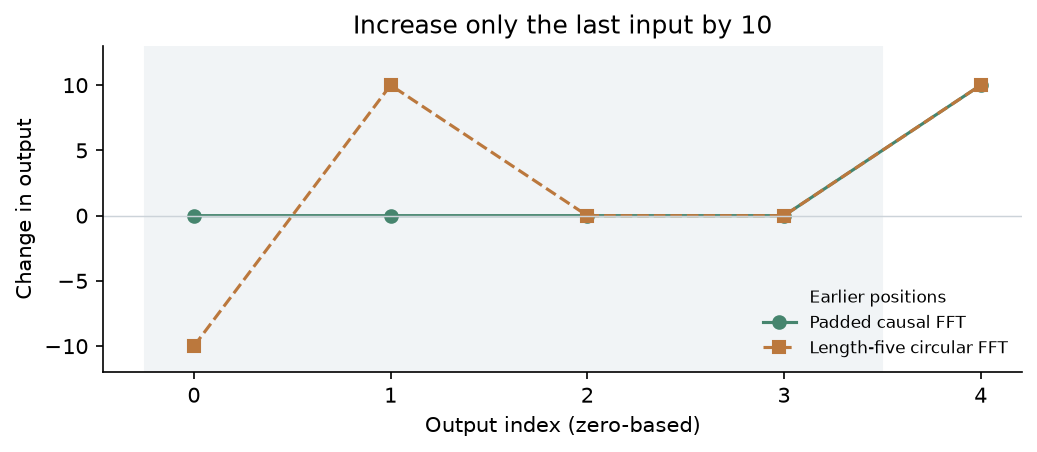

In [10]:
changed_u = conv_u.copy()
changed_u[-1] += 10
causal_change = fft_causal_convolution(changed_u, conv_h) - conv_causal
circular_changed = np.fft.irfft(
    np.fft.rfft(changed_u, n=5) * conv_h_short, n=5)
circular_change = circular_changed - conv_circular
np.testing.assert_allclose(causal_change, [0, 0, 0, 0, 10], rtol=0, atol=1e-12)
np.testing.assert_allclose(circular_change, [-10, 10, 0, 0, 10], rtol=0, atol=1e-12)
print("Causal change:", causal_change.round(10))
print("Circular change:", circular_change.round(10))

fig, ax = plt.subplots(figsize=(6.8, 2.9), constrained_layout=True)
ax.axvspan(-0.25, 3.5, color="#f1f4f6", label="Earlier positions")
ax.plot(range(5), causal_change, "o-", color=TEAL, label="Padded causal FFT")
ax.plot(range(5), circular_change, "s--", color=ORANGE, label="Length-five circular FFT")
ax.set(xticks=range(5), xlabel="Output index (zero-based)", ylabel="Change in output",
       title="Increase only the last input by 10", ylim=(-12, 13))
ax.axhline(0, color="#ccd3d9", lw=0.7)
ax.legend(frameon=False, fontsize=8, loc="lower right")
show_plot(fig)

## 7. Resume from a saved state

Splitting the input into chunks does not change the recurrence. A
chunk boundary is just a place to save the current state and resume
later. For this one-coordinate system the update is
$x_t=\tfrac34 x_{t-1}+u_t$, and $y_t=x_t$. The first two inputs give
$x_1=1$ and $x_2=\tfrac34\cdot1+4=\tfrac{19}{4}=4.75$.
The last state of the first chunk, `first_states[-1]`, is
a one-element vector containing $x_2$.

At the first input of the second chunk, the input is zero.
Resuming gives $x_3=\tfrac34\cdot4.75=3.5625$. Starting at
zero gives $x_3=0$. The subsequent inputs $2$ and $1$ are
identical in both runs, so their contributions cancel when
comparing the states. The difference is multiplied by
$3/4$ at each step.

| Global step $t$ | $u_t$ | Continue from $x_2$ | Reset after $t=2$ | Difference |
| --: | --: | --: | --: | --: |
| 3 | 0 | $3.5625$ | $0$ | $3.5625$ |
| 4 | 2 | $4.671875$ | $2$ | $2.671875$ |
| 5 | 1 | $4.50390625$ | $2.5$ | $2.00390625$ |

In general, after $j$ steps of the second chunk, the difference
is $(3/4)^j x_2$ for this scalar system. The saved state preserves
the effects of both earlier inputs in a single number. We can
verify the joined output and the joined state trace independently.

In [11]:
chunk_input = np.array([1.0, 4.0, 0.0, 2.0, 1.0])
chunk_transition = np.array([[0.75]])
chunk_write = np.array([1.0])
chunk_read = np.array([1.0])
chunk_model = (chunk_transition, chunk_write, chunk_read)

whole_output, whole_states = ssm_scan(chunk_input, *chunk_model)
first_output, first_states = ssm_scan(chunk_input[:2], *chunk_model)
resumed_output, resumed_states = ssm_scan(
    chunk_input[2:], *chunk_model, x0=first_states[-1],
)
reset_output, _ = ssm_scan(chunk_input[2:], *chunk_model)

joined_output = np.concatenate((first_output, resumed_output))
joined_states = np.concatenate((first_states, resumed_states), axis=0)
reset_joined = np.concatenate((first_output, reset_output))
expected_whole = np.array([1.0, 4.75, 3.5625, 4.671875, 4.50390625])
expected_reset = np.array([1.0, 4.75, 0.0, 2.0, 2.5])
expected_gap = 0.75 ** np.arange(1, 4) * first_states[-1, 0]
np.testing.assert_allclose(joined_output, whole_output, rtol=0, atol=1e-12)
np.testing.assert_allclose(joined_states, whole_states, rtol=0, atol=1e-12)
np.testing.assert_allclose(whole_output, expected_whole, rtol=0, atol=1e-12)
np.testing.assert_allclose(reset_joined, expected_reset, rtol=0, atol=1e-12)
np.testing.assert_allclose(
    resumed_output - reset_output, expected_gap, rtol=0, atol=1e-12,
)

print("Saved state", first_states[-1])
print("Whole scan", whole_output)
print("Joined, resumed", joined_output)
print("Joined, reset", reset_joined)
print("Resumed minus reset on the second chunk", expected_gap)

Saved state [4.75]
Whole scan [1.         4.75       3.5625     4.671875   4.50390625]
Joined, resumed [1.         4.75       3.5625     4.671875   4.50390625]
Joined, reset [1.   4.75 0.   2.   2.5 ]
Resumed minus reset on the second chunk [3.5625     2.671875   2.00390625]


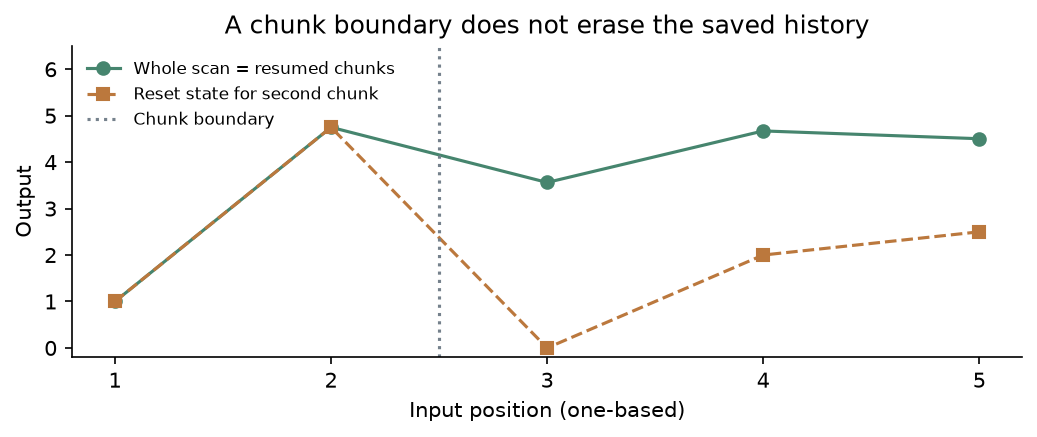

In [12]:
fig, ax = plt.subplots(figsize=(6.8, 2.8), constrained_layout=True)
positions = np.arange(1, 6)
ax.plot(positions, whole_output, "o-", color=TEAL, label="Whole scan = resumed chunks")
ax.plot(positions, reset_joined, "s--", color=ORANGE, label="Reset state for second chunk")
ax.axvline(2.5, color="#75818c", linestyle=":", label="Chunk boundary")
ax.set(xticks=positions, xlabel="Input position (one-based)", ylabel="Output",
       title="A chunk boundary does not erase the saved history", ylim=(-0.2, 6.5))
ax.legend(frameon=False, fontsize=8, loc="upper left")
show_plot(fig)

## 8. Move a zero gate

Think of the input gate as controlling what gets written into the
filter's history, and the output gate as controlling what gets
read out at the current position. Number positions from one in
this exercise, matching position 2 in the prompt. Let $x_t$ be the
input after its gate and $z_t$ the filtered value. With taps
$(1,1/2,1/4)$,

$$
z_t=x_t+\frac{1}{2} x_{t-1}+\frac{1}{4} x_{t-2}.
$$

Values of $x_t$ before position 1 are zero. The output gate then
multiplies $z_t$ by its entry at position $t$. It acts after the
filter, so its result does not get fed back into the filter.

If the input gate closes at position 2, it replaces the second
input $2$ with $0$ before filtering. Then $x=(1,0,1,1)$.
If only the output gate closes there, the filter sees all of
$x=(1,2,1,1)$. Compute the two filtered sequences row by row.

| Position $t$ | Filtered with input gate closed at 2 | Filtered with all input gates open |
| ---: | :--- | :--- |
| 1 | $1$ | $1$ |
| 2 | $0+\frac{1}{2}=\frac{1}{2}$ | $2+\frac{1}{2}=\frac{5}{2}$ |
| 3 | $1+0+\frac{1}{4}=\frac{5}{4}$ | $1+1+\frac{1}{4}=\frac{9}{4}$ |
| 4 | $1+\frac{1}{2}+0=\frac{3}{2}$ | $1+\frac{1}{2}+\frac{1}{2}=2$ |

With the zero on the input side, the output gate is all ones, so
the final output equals the filtered sequence
$(1,\frac{1}{2},\frac{5}{4},\frac{3}{2})$. With the zero on the output
side, only the filtered value at position 2 is suppressed.
The final output is $(1,0,\frac{9}{4},2)$.

In [13]:
from examples.ch13_state_spaces.model import hyena_stage

gate_u = np.array([1., 2., 1., 1.])
gate_open = np.ones_like(gate_u)
gate_zero_at_two = np.array([1., 0., 1., 1.])
gate_h = np.array([1., 0.5, 0.25])

gate_input_case = hyena_stage(
    gate_u, gate_zero_at_two, gate_open, gate_h,
)
gate_output_case = hyena_stage(
    gate_u, gate_open, gate_zero_at_two, gate_h,
)
gate_input_expected = (
    [1., 0., 1., 1.], [1., 0.5, 1.25, 1.5], [1., 0.5, 1.25, 1.5],
)
gate_output_expected = (
    [1., 2., 1., 1.], [1., 2.5, 2.25, 2.], [1., 0., 2.25, 2.],
)
gate_labels = ("Gated input", "Filtered values", "Final output")
for gate_title, gate_actual, gate_expected in (
    ("Zero input gate at position 2",
     gate_input_case, gate_input_expected),
    ("Zero output gate at position 2",
     gate_output_case, gate_output_expected),
):
    print(gate_title)
    for label, actual, expected in zip(
        gate_labels, gate_actual, gate_expected,
    ):
        np.testing.assert_array_equal(actual, expected)
        print(f"  {label:16s} {actual}")

Zero input gate at position 2
  Gated input      [1. 0. 1. 1.]
  Filtered values  [1.   0.5  1.25 1.5 ]
  Final output     [1.   0.5  1.25 1.5 ]
Zero output gate at position 2
  Gated input      [1. 2. 1. 1.]
  Filtered values  [1.   2.5  2.25 2.  ]
  Final output     [1.   0.   2.25 2.  ]


All these values are integers or binary fractions, so the
float64 results can be checked for exact equality. To isolate the
later effect of the closed input gate, compare the two
**filtered** sequences, before either output gate acts.

At position 3, the original second input $2$ would have
contributed $2\cdot\frac{1}{2}=1$ through lag one. At position 4,
it would have contributed $2\cdot\frac{1}{4}=\frac{1}{2}$ through lag
two. The closed input gate removes both contributions, so
**positions 3 and 4** are affected. Position 1 is earlier than
the changed input and cannot read it. The filter has no taps
beyond lag two, so the effect would also be gone at position 5
if we extended the sequence.

Position 2 itself shows why the placement matters. Closing the
input gate there leaves the earlier contribution $\frac{1}{2}$
from position 1. Closing the output gate there zeroes the whole
filtered value, but the input at position 2 remains available to
later filter calls.

## 9. Account for the initial state (optional)

With a nonzero initial state, the system can produce an output
before any nonzero input arrives. Here the first input is zero, but
the initial state $(1,-1)$ becomes $(1/2,-1/4)$ after the first
update. Reading with $C=(2,1)$ gives
$2(1/2)-1/4=3/4$. A zero-state convolution gives zero at that
step and needs a separate term for the initial state.

For each input, halve the first coordinate of the previous state,
quarter the second, and add the same input to both coordinates.
Then read twice the first coordinate plus the second.

| $t$ | Input $u_t$ | State $x_t$ | Output $Cx_t$ |
| --: | --: | :-- | --: |
| 1 | 0 | $(0.5,-0.25)$ | 0.75 |
| 2 | 3 | $(3.25,2.9375)$ | 9.4375 |
| 3 | 1 | $(2.625,1.734375)$ | 6.984375 |
| 4 | 0 | $(1.3125,0.43359375)$ | 3.05859375 |

Linearity lets us separate the response into two parts. The
zero-state part follows the inputs starting from $0$. The
initial-state part follows $x_0$ with all inputs set to zero.
At step $t$ the latter has applied the transition $t$ times.
Applying the readout to both parts gives

$$
y_t=\sum_{j=0}^{t-1} h_j u_{t-j}
    + C\overline A^t x_0,
\qquad h_j=C\overline A^j\overline B.
$$

The filter starts at lag zero because the current input is read
immediately. The correction starts at $t=1$ because the first
returned output is read after the first transition. Here
$h_j=2(1/2)^j+(1/4)^j$, giving taps
$(3,1.25,0.5625,0.265625)$.
For the correction, the two coordinates of
$\overline A^t x_0$ are $(1/2)^t$ and $-(1/4)^t$.
Reading them gives $2(1/2)^t-(1/4)^t$.

| $t$ | Zero-state convolution | Initial-state correction | Sum |
| --: | --: | --: | --: |
| 1 | 0 | 0.75 | 0.75 |
| 2 | 9 | 0.4375 | 9.4375 |
| 3 | 6.75 | 0.234375 | 6.984375 |
| 4 | 2.9375 | 0.12109375 | 3.05859375 |

In [14]:
correction_input = np.array([0.0, 3.0, 1.0, 0.0])
correction_transition = np.diag([0.5, 0.25])
correction_write = np.array([1.0, 1.0])
correction_read = np.array([2.0, 1.0])
initial_state = np.array([1.0, -1.0])

with_initial, with_initial_states = ssm_scan(
    correction_input, correction_transition,
    correction_write, correction_read, x0=initial_state,
)
correction_kernel = ssm_kernel(
    correction_transition, correction_write, correction_read,
    length=len(correction_input),
)
zero_state = causal_convolution(correction_input, correction_kernel)
initial_response = np.array([
    correction_read @ np.linalg.matrix_power(correction_transition, t)
    @ initial_state
    for t in range(1, len(correction_input) + 1)
])
corrected = zero_state + initial_response

The arrays are ready to compare. The next cell checks
them against the hand calculations before printing them.

In [15]:
expected_initial_states = [
    [0.5, -0.25], [3.25, 2.9375], [2.625, 1.734375],
    [1.3125, 0.43359375],
]
np.testing.assert_allclose(
    with_initial_states, expected_initial_states, rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    zero_state, [0, 9, 6.75, 2.9375], rtol=0, atol=1e-12,
)
np.testing.assert_allclose(
    initial_response, [0.75, 0.4375, 0.234375, 0.12109375],
    rtol=0, atol=1e-12,
)
np.testing.assert_allclose(corrected, with_initial, rtol=0, atol=1e-12)

print("Kernel taps", correction_kernel)
print("t   zero-state      initial       corrected      scan")
for t, (base, extra, total, scanned) in enumerate(
    zip(zero_state, initial_response, corrected, with_initial), start=1,
):
    print(f"{t}   {base:>10.8f}   {extra:>10.8f}   "
          f"{total:>10.8f}   {scanned:>10.8f}")

Kernel taps [3.       1.25     0.5625   0.265625]
t   zero-state      initial       corrected      scan
1   0.00000000   0.75000000   0.75000000   0.75000000
2   9.00000000   0.43750000   9.43750000   9.43750000
3   6.75000000   0.23437500   6.98437500   6.98437500
4   2.93750000   0.12109375   3.05859375   3.05859375


The two outputs agree within the float64 absolute tolerance
$10^{-12}$ with relative tolerance zero. If we started the powers
at zero, the first correction would be $Cx_0=1$, which reads the
state before processing $u_1$. The scan returns the output after
the update, so the correct first correction is $3/4$.

## 10. Count streaming storage (optional)

Count numerical history carried across a boundary before the next input
arrives, per feature, once the direct filter's history is filled.

| Filter length in direct method | SSM with 16 state coordinates | Direct convolution history |
| --- | --- | --- |
| 1024 | 16 numbers | $1024-1=1023$ numbers |
| 2048 | 16 numbers | $2048-1=2047$ numbers |

The next incoming sample supplies lag zero. The direct implementation
therefore retains the $L-1$ preceding samples, not $L$ past samples.
Doubling $L$ adds 1024 carried values; the SSM's chosen state width stays
16. Filter taps and transition weights are parameters, while temporary
products and sums are workspaces. They are excluded by the question.
The teaching helper's full state trace is also excluded: saving that
trace for $n$ inputs would require $16n$ values.

**Smaller storage does not establish identical outputs for an arbitrary
filter.** The SSM can realize filters of the form
$k_\ell=C\overline A^\ell\overline B$ with its chosen 16-coordinate
state. That structured family need not contain a given arbitrary
1024-tap filter. Exact recurrence--convolution equivalence applies to a
filter generated by the SSM itself. This storage comparison does not
claim equal expressive power or predict a runtime speedup.

In [16]:
state_width = 16
for length, expected_history in [(1024, 1023), (2048, 2047)]:
    history = length - 1
    assert history == expected_history
    print(f"Filter length {length}: SSM {state_width}; direct history {history}")
assert (2048 - 1) - (1024 - 1) == 1024

Filter length 1024: SSM 16; direct history 1023
Filter length 2048: SSM 16; direct history 2047


## 11. Check a changing rule (optional)

Since $x_0=0$, the first state is $x_1=u_1$, regardless of $a_1$.
Substituting the earlier states gives

$$
y_2=\tfrac12u_1+u_2,\qquad
y_3=\tfrac34(\tfrac12u_1+u_2)+u_3
   =\tfrac38u_1+\tfrac34u_2+u_3.
$$

The coefficient of $u_1$ in $y_2$ is $1/2$. The coefficient of $u_2$
in $y_3$ is $3/4$. Both have lag one, but cross different transitions.
One fixed lag-one tap cannot equal both values. The coefficient of
$u_1$ in $y_3$ is the product $a_3a_2=3/8$.

For these prescribed factors, the whole map is multiplication by

$$
\begin{pmatrix}1&0&0\\1/2&1&0\\3/8&3/4&1\end{pmatrix}.
$$

It is still **linear in the inputs**, because its coefficients do not
depend on them. It is not time invariant: the first subdiagonal is
not constant. A fixed convolution would have the same tap along each
subdiagonal. If the retention factors are instead computed from the
inputs, the resulting complete map is generally nonlinear as well.
These are two different properties. Losing time invariance alone is
enough to lose the one-filter representation.

In [17]:
def changing_scan(inputs):
    state = 0.0
    outputs = []
    for retention, value in zip([0.25, 0.5, 0.75], inputs):
        state = retention * state + value
        outputs.append(state)
    return np.array(outputs)

impulses = np.eye(3)
changing_matrix = np.column_stack([changing_scan(u) for u in impulses])
expected_matrix = np.array([[1, 0, 0], [0.5, 1, 0], [0.375, 0.75, 1]])
np.testing.assert_array_equal(changing_matrix, expected_matrix)
u, v = np.array([2, -1, 3]), np.array([1, 4, 0])
np.testing.assert_array_equal(changing_scan(2*u + v), 2*changing_scan(u) + changing_scan(v))
print("Input-to-output matrix:", changing_matrix, sep="\n")
print("Lag-one coefficients:", changing_matrix[1, 0], changing_matrix[2, 1])
print("Coefficient of u1 in y3:", changing_matrix[2, 0])

Input-to-output matrix:
[[1.    0.    0.   ]
 [0.5   1.    0.   ]
 [0.375 0.75  1.   ]]
Lag-one coefficients: 0.5 0.75
Coefficient of u1 in y3: 0.375


## Checks

All eleven exercises have complete solutions. The executed checks cover
state collisions, lag indexing, cancellation in the readout, discretization,
scan/direct/FFT agreement, circular wraparound, future perturbations,
chunk continuation, gate placement, initial-state corrections, storage
counts, and linear but time-varying updates. Floating-point comparisons
use explicit tolerances; plots display the computed arrays.

## Next Steps

Change one retention factor or one gate and predict which later outputs
will change before rerunning. Keep a filter's lag indices separate from
the sequence's absolute positions. The next chapter lets the input
control the state update itself, so a single fixed lag filter will
no longer describe the complete sequence.